# Lab 00: How to set up the lab environment

**CPU | API key: `OPENAI_API_KEY` for Part D**

## Goal

Check in one run that your environment is ready for every lab in this repository. Set it up first with this lab's
README (Colab, or your own machine with `uv` or `pip`), then run every cell from the top. When the last cell shows ✅
on every line, you are ready for Lab 01.

## What you will learn

- What the first two cells of every lab do, on Colab and on your own machine.
- How to check in one run that your packages, the data files, the shop's Ops API and your key all work.
- Where the model every lab uses is set, and how to change it.
- How to find what a failed check means and fix it with the troubleshooting table.

## The first two cells

Every lab in this repository opens with the same two cells.

**Setup** finds the repository folder. On Colab it first copies the repository into the session with a shallow `git
clone` (only the latest version of each file) and installs the packages in `requirements.txt`. On your own machine you
installed the packages once (route B or C in the README), so the cell installs nothing.

**Config** reads the model names from `models.env` in the repository folder, the one file that sets them for every
lab. If you put the same name in your `.env` file or in an environment variable, your value wins. Then it looks for
your OpenAI key: in the environment, in `.env`, then in Colab Secrets. It prints where it found the key, never the
key.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


The last three lines find the repository folder. `next(...)` looks in the folder the notebook runs in, then in each
folder above it, and takes the first one that holds `models.env`. Adding that folder to `sys.path` lets every lab
import from `shared/`, as the next cell does.

On Colab the install adds the missing packages and upgrades `openai` from the 2.x series to 3.24.0. pip then says
*"you may need to restart the kernel"*; in a fresh session you need not, because nothing has loaded the old `openai`
yet.

⚠️ If you ran other cells first, the old `openai` may already be loaded, and Part D then fails with `ImportError:
cannot import name ... from 'openai...'`. Use **Runtime → Restart session** and run the notebook from the top; the
clone is skipped the second time.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


`CHAT_MODEL` is the model every lab calls, `JUDGE_MODEL` grades answers in the evaluation lab, and `EMBED_MODEL` turns
text into numbers for search. `REASONING_EFFORT` stays empty for a model without that setting; the comment above it in
`models.env` lists the values a reasoning model accepts. No notebook names a model in its code. To use another model in every lab, change
`CHAT_MODEL` in `models.env`; to try one on your machine only, set `CHAT_MODEL` in your `.env`, which wins. The outputs saved in this notebook come from `gpt-4o-mini-2024-07-18` on 13 Oct 2026.

If the key line says `not found`, Parts A to C still run. Add the key before Part D (see the troubleshooting table at
the end).

The map below shows what each part checks.

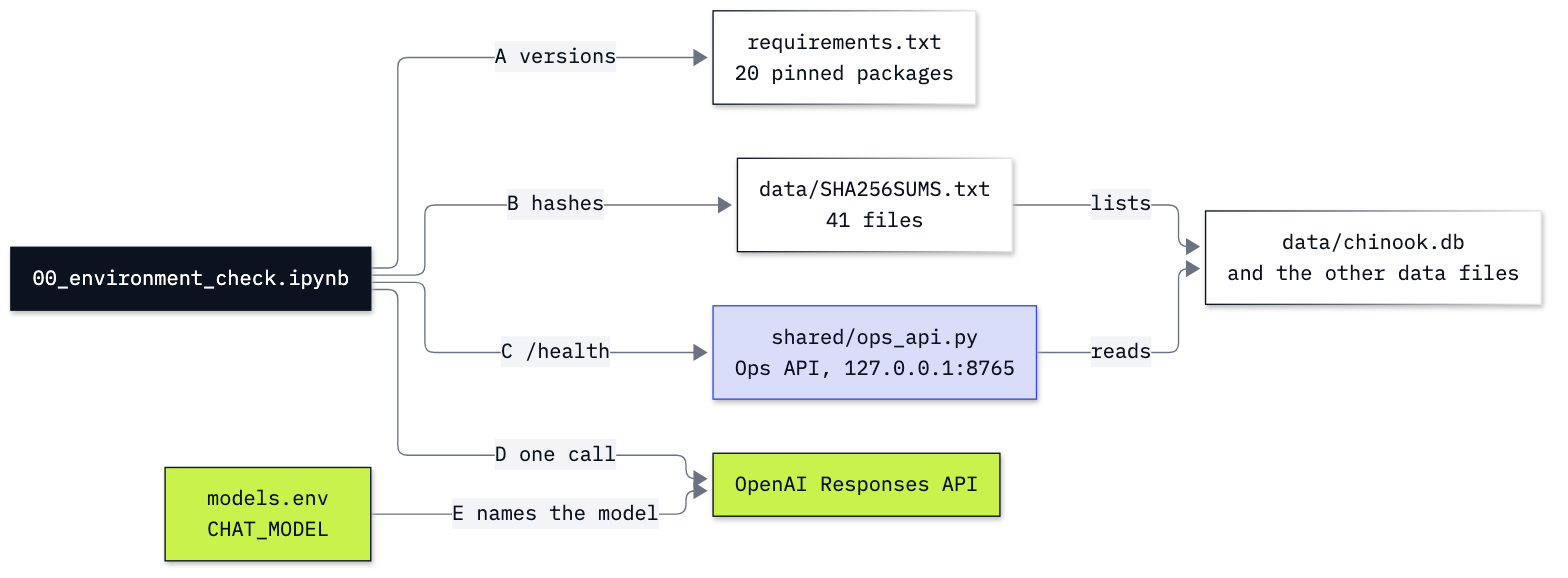

In [3]:
from IPython.display import Image
Image(filename=ROOT / "00_Environment_Check" / "resources" / "lab00_checks.png", width=760)

---

## Part A: Check the packages

Every saved output in these labs came from the package versions pinned in `requirements.txt`. A different version can
print a different result, warning or error, so this cell compares each pin with what is installed. `version(name)`
asks the environment the notebook runs in, which is the one that matters: a terminal can use a different Python.

In [4]:
import platform
from importlib.metadata import version, PackageNotFoundError

pinned_count, different = 0, []
for line in (ROOT / "requirements.txt").read_text().splitlines():
    if line and not line.startswith("#"):
        name, pinned = line.split("==")          # one "name==version" line per package
        pinned_count += 1
        try:
            installed = version(name)
        except PackageNotFoundError:
            installed = "missing"
        if installed != pinned:
            different.append(f"{name} {installed}, pin {pinned}")

print("Python", platform.python_version())
print(pinned_count, "pinned packages,", len(different), "different")
for line in different:
    print("  ", line)

Python 3.13.5
20 pinned packages, 0 different


A pass is Python 3.13 and 0 packages different. Colab runs Python 3.13, and both local routes in the README use 3.13 too.
If a package is `missing` or different, see the troubleshooting table. Do not upgrade a pinned package yourself, even
to silence a warning: the later labs were run and written on these versions.

---

## Part B: Check the data files

The labs read the shop's data from `data/`: its policies and tickets, the support handbook, and `chinook.db`, the
database of a fictional music shop. Many checkpoints depend on the exact text. `data/SHA256SUMS.txt` lists a SHA-256
hash of every file: a 64-character fingerprint of its bytes that changes completely when one byte changes. The cell
hashes each file and compares.

In [ ]:
import hashlib

DATA = ROOT / "data"
sums = (DATA / "SHA256SUMS.txt").read_text().splitlines()
changed, missing = [], []
for line in sums:
    expected, name = line.split("  ")             # the hash, two spaces, the file's path
    path = DATA / name
    if not path.exists():
        missing.append(name)
    elif hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        changed.append(name)

print(f"{len(sums) - len(changed) - len(missing)} of {len(sums)} files match")
print("Changed:", changed or "none")
print("Missing:", missing or "none")

A pass is 41 of 41 files, none changed and none missing. Opening a data file in an editor and saving it can be enough to change its
hash, which is why the labs only read `data/`. If a file fails or is missing, get it back from the repository
(troubleshooting table).

---

## Part C: Check the Ops API

The Ops API is the shop's small web service: find a customer, list their invoices, file a refund request. The copilot
calls it from Lab 05 on. You call it in the labs; you do not write it (its code is in `shared/ops_api.py`).

`start_ops_api()` runs it inside this notebook, in a background thread, on `127.0.0.1` (your own machine or your Colab
session, not the internet) at port 8765. If a service already answers on that port, for example one that another
notebook started, it reuses that one and prints *Ops API already running*. It returns the server when this notebook started it,
and `None` when another notebook did, since only that notebook can stop it. The
cell starts it, asks `/health`, the address a web service answers when it is up, and stops it again if it started
it.

In [6]:
import httpx
from shared.ops_api import start_ops_api

server = start_ops_api(port=8765)
health = httpx.get("http://127.0.0.1:8765/health")
print(health.status_code, health.json())

if server:            # stop it only if this notebook started it
    server.should_exit = True

Ops API started at http://127.0.0.1:8765
200 {'status': 'ok'}


A pass is `200 {'status': 'ok'}`: status 200 means the request worked. Each lab that uses the Ops API starts it again in
its own setup.

---

## Part D: Check that the model answers

This part proves your key reaches the chat model.

⚠️ It sends one short request with your key, a small fraction of a US cent. Without a key it stops with
`OpenAIError: Missing credentials`: add the key (see the troubleshooting table), run the config cell again, then this
part.

The call uses OpenAI's own Python library. `client.responses.create` sends the question with the model name read from
`models.env`; Lab 01 starts from this call and explains what comes back. Here it only has to answer.

In [7]:
from openai import OpenAI

client = OpenAI()
question = "How long does a digital download link last?"
response = client.responses.create(model=settings["CHAT_MODEL"], input=question)

print(response.output_text)
print("\nanswered by:", response.model)

The duration that a digital download link lasts can vary depending on the provider or platform you purchased from. Common practices include:

1. **24 Hours**: Some sites may limit access to the link for just 24 hours after the initial download.
  
2. **7 to 30 Days**: Many platforms allow a window from a week to a month before the link expires.

3. **Unlimited/No Expiration**: Some services offer links that don't expire, allowing unlimited downloads as long as the service remains active.

Always check the terms and conditions or FAQs of the specific site for precise details.

answered by: gpt-4o-mini-2024-07-18


A pass is any reply. Ours listed how long links usually last (24 hours, 7 to 30 days, or no expiry) and told us to
check the seller's terms. Chinook has its own rule for download links, and this call did not send it; Lab 01 starts
from there. `response.model` names the model that answered: `gpt-4o-mini` in `models.env` is an alias, and OpenAI reports the
dated version behind it.

---

## Check that you are ready

One line per part. Copy the output into your notes: later labs compare their numbers with runs on other machines. If
you skipped a part, this cell stops with a `NameError`: run that part, then this cell again.

In [ ]:
from datetime import date

checks = {
    "A  Python 3.13 and the pinned packages": platform.python_version().startswith("3.13") and not different,
    "B  data files unchanged": not changed and not missing,
    "C  Ops API answers": health.status_code == 200,
    "D  the model answers": bool(response.output_text),
}

print("Run on", date.today().isoformat(), "|", "Colab" if IN_COLAB else platform.system(),
      "| Python", platform.python_version(), "|", response.model)
for name, passed in checks.items():
    print("✅" if passed else "❌", name)

Every line passes: you are ready for Lab 01. A ❌ names the part to look at; the troubleshooting table below lists the usual
causes.

### Checkpoint

| Part | You should see | Our run |
|---|---|---|
| A | Python 3.13.x; 0 packages different | Python 3.13.5; 20 pinned packages, 0 different |
| B | 41 of 41 files match; changed: none; missing: none | 41 of 41; changed: none; missing: none |
| C | `200 {'status': 'ok'}` | `200 {'status': 'ok'}` |
| D | a reply in any wording, and the model that answered | a list of how long links usually last; `gpt-4o-mini-2024-07-18` |

## What you can do now

- Open any lab in this repository on Colab or locally; its first two cells are the ones you ran here.
- Check in one run that your packages, data files, the Ops API and your key work.
- Find what a failed check means and fix it with the troubleshooting table.
- Find the line in `models.env` that chooses the model, and change it for every lab or only on your machine.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| Part A shows a Python other than 3.13 (local) | the notebook runs on another kernel | choose the repository's `.venv` kernel; install the packages first (route B or C in the README) |
| A package shows as different or `missing` | the setup cell did not run, or Colab still had an older version loaded | run the setup cell; on Colab use Runtime → Restart session, then run from the top |
| `ModuleNotFoundError: No module named 'shared'` | the setup cell was skipped, or the notebook was opened outside the repository | run the setup cell first; locally, open the notebook from inside the repository folder |
| `StopIteration` in the setup cell (local) | the notebook is not inside the repository folder | open it from the cloned repository, where `models.env` sits |
| A data file is listed as missing | the copy of the repository is incomplete, or the file was moved or deleted | locally, `git checkout -- data/<file>`; on Colab, delete the folder and run the setup cell again |
| A data file is listed as changed | a file was opened and saved by an editor | locally, `git checkout -- data/<file>`; on Colab, delete the folder and run the setup cell again |
| `Ops API did not start on port 8765` | another program, not the Ops API, uses the port | restart the kernel; if it still fails, use `start_ops_api(port=8766)` and that port in the `/health` address |
| The config cell says the key is `not found`, or Part D stops with `OpenAIError: Missing credentials` | no key in the environment, `.env` or Colab Secrets | Colab: add `OPENAI_API_KEY` under Secrets (key icon) and switch on notebook access; locally: put it in `.env`. Then run the config cell again |
| `AuthenticationError` in Part D | the key is wrong or was revoked | paste the key again; ask the instructor if it is a class key |
| `NotFoundError`, status 404: *The model `...` does not exist or you do not have access to it.* | `CHAT_MODEL` is misspelt, or your account cannot use that model | check `models.env` and any `CHAT_MODEL` line in `.env` |
| `RateLimitError` | a shared class key reached its limit | wait a minute and run the cell again; tell the instructor if it repeats |


## Resources

- [uv: working on projects](https://docs.astral.sh/uv/guides/projects/): `uv sync`, `.python-version` and the lock
  file
- [Python `hashlib`](https://docs.python.org/3/library/hashlib.html): the SHA-256 hashes in Part B
- [Chinook Database](https://github.com/lerocha/chinook-database): the sample database's origin and licence
- [OpenAI: text generation](https://developers.openai.com/api/docs/guides/text): `client.responses.create` and
  `output_text`, the call in Part D
- [OpenAI: models](https://developers.openai.com/api/docs/models): the models you can name in `models.env`, with their
  prices and limits

Next: [Lab 01: How to build a tool-calling agent](../01_First_Chain_And_Tool/README.md). Back to [the lab
list](../README.md).